# TikTok: Claims Classification Data (Machine Learning Stage)

Case study from the Google Advanced Data Analytics Professional Certificate (Course 5: The Nuts and Bolts of Machine Learning). Building and comparing random forest and XGBoost models to classify TikTok videos as claims or opinions.

# **Classify videos using machine learning**

## Plan

How would you proceed?

lean the data, engineer features, split 60/20/20, tune models, pick a champion on validation, and test once.

### Imports and data loading

In [75]:
# Import packages for data manipulation
import pandas as pd
import numpy as np


# Import packages for data visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Import packages for data preprocessing
import sklearn.model_selection as ms
import sklearn.metrics as metrics

# Import packages for data modeling
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier, plot_importance

In [76]:
# Load dataset into dataframe
data = pd.read_csv("tiktok_dataset.csv")

## Analyze

### Data exploration

In [77]:
# Display first few rows
data.head()


,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


In [78]:
# Get number of rows and columns
data.shape


(19382, 12)

In [79]:
# Get data types of columns
data.dtypes


#                             int64
claim_status                 object
video_id                      int64
video_duration_sec            int64
video_transcription_text     object
verified_status              object
author_ban_status            object
video_view_count            float64
video_like_count            float64
video_share_count           float64
video_download_count        float64
video_comment_count         float64
dtype: object

In [80]:
# Get basic information
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19382 entries, 0 to 19381
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   #                         19382 non-null  int64  
 1   claim_status              19084 non-null  object 
 2   video_id                  19382 non-null  int64  
 3   video_duration_sec        19382 non-null  int64  
 4   video_transcription_text  19084 non-null  object 
 5   verified_status           19382 non-null  object 
 6   author_ban_status         19382 non-null  object 
 7   video_view_count          19084 non-null  float64
 8   video_like_count          19084 non-null  float64
 9   video_share_count         19084 non-null  float64
 10  video_download_count      19084 non-null  float64
 11  video_comment_count       19084 non-null  float64
dtypes: float64(5), int64(3), object(4)
memory usage: 1.8+ MB


In [81]:
# Generate basic descriptive stats
data.describe()


,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
count,19382.000000,1.938200e+04,19382.000000,19084.000000,19084.000000,19084.000000,19084.000000,19084.000000
mean,9691.500000,5.627454e+09,32.421732,254708.558688,84304.636030,16735.248323,1049.429627,349.312146
std,5595.245794,2.536440e+09,16.229967,322893.280814,133420.546814,32036.174350,2004.299894,799.638865
min,1.000000,1.234959e+09,5.000000,20.000000,0.000000,0.000000,0.000000,0.000000
25%,4846.250000,3.430417e+09,18.000000,4942.500000,810.750000,115.000000,7.000000,1.000000
50%,9691.500000,5.618664e+09,32.000000,9954.500000,3403.500000,717.000000,46.000000,9.000000
75%,14536.750000,7.843960e+09,47.000000,504327.000000,125020.000000,18222.000000,1156.250000,292.000000
max,19382.000000,9.999873e+09,60.000000,999817.000000,657830.000000,256130.000000,14994.000000,9599.000000


Check for and handle missing values.

In [82]:
# Check for missing values
data.isna().sum()

#                             0
claim_status                298
video_id                      0
video_duration_sec            0
video_transcription_text    298
verified_status               0
author_ban_status             0
video_view_count            298
video_like_count            298
video_share_count           298
video_download_count        298
video_comment_count         298
dtype: int64

In [83]:
# Drop rows with missing values
data = data.dropna(axis=0)


In [84]:
# Display first few rows after handling missing values

data.head()

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


Check for and handle duplicates.

In [85]:
# Check for duplicates
data.duplicated().sum()

0

Check for and handle outliers.

In [86]:
# Tree Models are Robust to Outliers

Check class balance.

In [87]:
# Check class balance
data["claim_status"].value_counts(normalize=True)


claim_status
claim      0.503458
opinion    0.496542
Name: proportion, dtype: float64

## Construct

### Feature engineering

In [88]:
# Extract the length of each `video_transcription_text` and add this as a column to the dataframe
data["txt_len"] = data["video_transcription_text"].str.len()


In [89]:
# Calculate the average text_length for claims and opinions
data.groupby("claim_status")["txt_len"].mean()


claim_status
claim      95.376978
opinion    82.722562
Name: txt_len, dtype: float64

<Axes: xlabel='txt_len', ylabel='Count'>

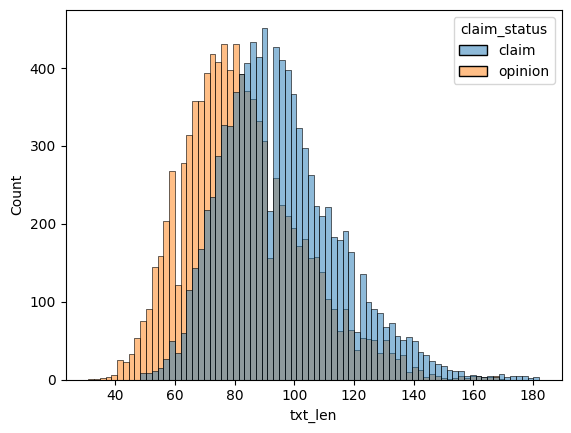

In [90]:
# Visualize the distribution of `text_length` for claims and opinions
# Create two histograms in one plot
sns.histplot(data=data, x="txt_len",hue="claim_status")


**Feature selection and transformation**

In [91]:
# Create a copy of the X data
x = data.copy()

# Drop unnecessary columns
x = x.drop(["#", "video_id","video_transcription_text"], axis =1)

# Encode target variable
x["claim_status"] = np.where(x["claim_status"] == "opinion", 0, 1)

# Dummy encode remaining categorical values
x = pd.get_dummies(x,columns = ["verified_status", "author_ban_status"], drop_first = True)


### Split the data

In [92]:
# Isolate target variable
y = x["claim_status"]


In [93]:
# Isolate features
x = x.drop(["claim_status"], axis =1)

# Display first few rows of features dataframe
x.head()


,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,txt_len,verified_status_verified,author_ban_status_banned,author_ban_status_under review
0,59,343296.0,19425.0,241.0,1.0,0.0,97,False,False,True
1,32,140877.0,77355.0,19034.0,1161.0,684.0,107,False,False,False
2,31,902185.0,97690.0,2858.0,833.0,329.0,137,False,False,False
3,25,437506.0,239954.0,34812.0,1234.0,584.0,131,False,False,False
4,19,56167.0,34987.0,4110.0,547.0,152.0,128,False,False,False


### Create train/validate/test sets

The data is first split 80/20 into training and testing sets. The training set is then split 75/25 into training and validation sets, resulting in a final ratio of 60/20/20 for train/validate/test sets.

In [94]:
# Split the data into training and testing sets
x_train, x_test, y_train, y_test = ms.train_test_split(x,y,test_size=0.20, random_state=7) 


In [95]:
# Split the training data into training and validation sets
x_train2, x_val, y_train2, y_val = ms.train_test_split(x_train,y_train,test_size=0.25, random_state=7)


In [96]:
# Get shape of each training, validation, and testing set
x_train.shape, x_test.shape, y_train.shape, y_test.shape, x_train2.shape, x_val.shape, y_train2.shape, y_val.shape

((15267, 10),
 (3817, 10),
 (15267,),
 (3817,),
 (11450, 10),
 (3817, 10),
 (11450,),
 (3817,))

### Build models

#### **Build a random forest model**

Hyperparameters are tuned with cross-validation, and the model that performs best on recall is selected.

In [97]:
# Instantiate the random forest classifier
rf = RandomForestClassifier(random_state=7)

# Create a dictionary of hyperparameters to tune
cv_params = {'max_depth': [5, 7, None],
             'max_features': [0.3, 0.6],
            #  'max_features': 'auto'
             'max_samples': [0.7],
             'min_samples_leaf': [1,2],
             'min_samples_split': [2,3],
             'n_estimators': [75,100,200],
             }

# Define a list of scoring metrics to capture
scoring = ['accuracy', 'precision', 'recall', 'f1']

# Instantiate the GridSearchCV object
gscv = ms.GridSearchCV(rf,cv_params, scoring=scoring, cv=5,refit="recall")


In [98]:
### Fit the model to the data 
gscv.fit(x_train2,y_train2)


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=7),
             param_grid={'max_depth': [5, 7, None], 'max_features': [0.3, 0.6],
                         'max_samples': [0.7], 'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 3],
                         'n_estimators': [75, 100, 200]},
             refit='recall', scoring=['accuracy', 'precision', 'recall', 'f1'])

In [118]:
# Examine best recall score
gscv.best_score_


0.989771540146194

In [119]:
# Examine best parameters
gscv.best_params_


{'max_depth': 7,
 'max_features': 0.6,
 'max_samples': 0.7,
 'min_samples_leaf': 1,
 'min_samples_split': 3,
 'n_estimators': 75}

Check the precision score to make sure the model isn't labeling everything as claims.

In [150]:
# Access the GridSearch results and convert it to a pandas df
results = pd.DataFrame(gscv.cv_results_)

# Examine the GridSearch results df at column `mean_test_precision` in the best index
results["mean_test_precision"][gscv.best_index_]


0.9996498905237546

#### **Build an XGBoost model**

In [122]:
# Instantiate the XGBoost classifier
xgb = XGBClassifier(objective='binary:logistic', random_state=7)

# Create a dictionary of hyperparameters to tune
cv_params = {'max_depth': [4,8,12],
             'min_child_weight': [3, 5],
             'learning_rate': [0.01, 0.1],
             'n_estimators': [300, 500]
             }

# Define a list of scoring metrics to capture
# Instantiate the GridSearchCV object
xgbcv = ms.GridSearchCV(xgb, cv_params, scoring=scoring, cv=5, refit='recall')

In [123]:
# Fit the model to the data
xgbcv.fit(x_train2, y_train2)


GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, gamma=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=None,...
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None,
                                     random_state=7, ...),
             param_grid={'learning_rate': [0.01, 0.1], 'max_depth': [4, 8, 12],
                         'min_child_weight': [3, 5],
                         'n_estimators': [300, 500]},
             refit='recall', scoring=['accuracy', 'precision', 'recall', 'f1'])

In [124]:
# Examine best recall score
xgbcv.best_score_


0.9887315284819497

In [125]:
# Examine best parameters
xgbcv.best_params_


{'learning_rate': 0.1,
 'max_depth': 4,
 'min_child_weight': 3,
 'n_estimators': 300}

In [126]:
# Access the GridSearch results and convert it to a pandas df
xgb_results = pd.DataFrame(xgbcv.cv_results_)

# Examine the GridSearch results df at column `mean_test_precision` in the best index
xgb_results["mean_test_precision"][xgbcv.best_index_]

0.9991243392323603

## Execute

### Evaluate models

#### **Random forest**

In [127]:
# Use the random forest "best estimator" model to get predictions on the validation set
y_pred = gscv.best_estimator_.predict(x_val)

In [128]:
# Display the predictions on the validation set
y_pred

array([1, 0, 1, ..., 1, 0, 1])

In [129]:
# Display the true labels of the validation set
y_val

925      1
12009    0
2419     1
5803     1
5003     1
        ..
16908    0
12042    0
7026     1
13538    0
8099     1
Name: claim_status, Length: 3817, dtype: int64

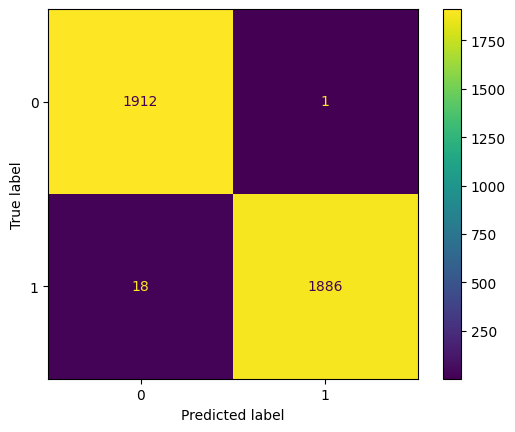

In [131]:
# Create a confusion matrix to visualize the results of the classification model
# Compute values for confusion matrix
cm = metrics.confusion_matrix(y_val,y_pred)

# Create display of confusion matrix using ConfusionMatrixDisplay()
display = metrics.ConfusionMatrixDisplay(confusion_matrix = cm, display_labels=None)

# Plot confusion matrix
display.plot()

# Display plot



In [134]:
# Create a classification report
# Create classification report for random forest model
print(metrics.classification_report(y_val, y_pred, target_names=["opinion", "claim"]))


              precision    recall  f1-score   support

     opinion       0.99      1.00      1.00      1913
       claim       1.00      0.99      0.99      1904

    accuracy                           1.00      3817
   macro avg       1.00      1.00      1.00      3817
weighted avg       1.00      1.00      1.00      3817



#### **XGBoost**

In [139]:
# Use the best estimator to predict on the validation data
y_pred = xgbcv.best_estimator_.predict(x_val)

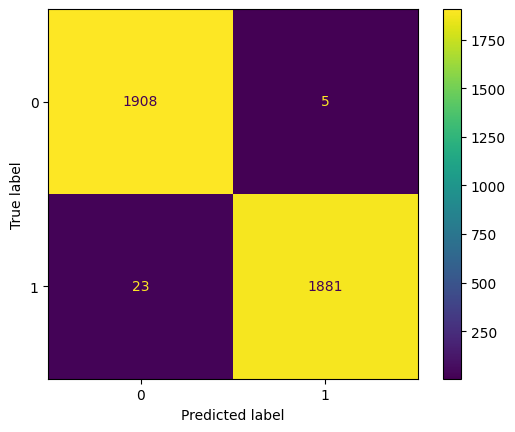

In [140]:
# Compute values for confusion matrix
cm2 = metrics.confusion_matrix(y_val,y_pred)

# Create display of confusion matrix using ConfusionMatrixDisplay()
display2 = metrics.ConfusionMatrixDisplay(confusion_matrix = cm2, display_labels=None)

# Plot confusion matrix
display2.plot()

# Display plot


In [142]:
# Create a classification report
target_labels = ['opinion', 'claim']
print(metrics.classification_report(y_val, y_pred, target_names=["opinion", "claim"]))

              precision    recall  f1-score   support

     opinion       0.99      1.00      0.99      1913
       claim       1.00      0.99      0.99      1904

    accuracy                           0.99      3817
   macro avg       0.99      0.99      0.99      3817
weighted avg       0.99      0.99      0.99      3817



### Use champion model to predict on test data

In [145]:
y_pred = gscv.best_estimator_.predict(x_test)

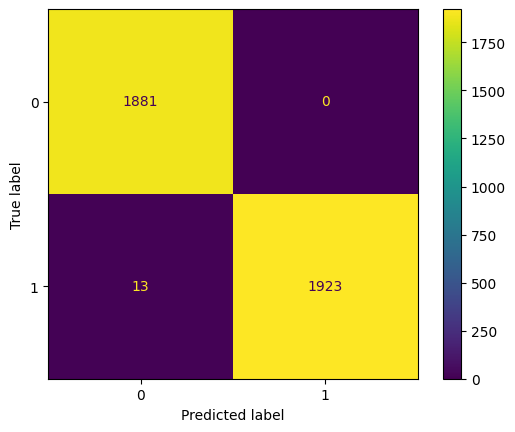

In [146]:
# Compute values for confusion matrix
cm3 = metrics.confusion_matrix(y_test, y_pred)

# Create display of confusion matrix
display3 = metrics.ConfusionMatrixDisplay(confusion_matrix=cm3, display_labels=None)

# Plot confusion matrix
display3.plot()

# Display plot


#### **Feature importances of champion model**

In [149]:
importances = gscv.best_estimator_.feature_importances_
rf_importances = pd.Series(importances, index=x_test.columns)


### Conclusion

1. **Would you recommend using this model? Why or why not?**

2. **What was your model doing? Can you explain how it was making predictions?**

3. **Are there new features that you can engineer that might improve model performance?**

4. **What features would you want to have that would likely improve the performance of your model?**

Recommend the model? Yes, it's accurate. But the near-perfect scores mean view count may be doing most of the work, so test it on new data.

How it predicts: Many trees vote, mostly using view count and engagement metrics.

New features to engineer: Text-based features such as keywords or sentiment.

Helpful extra features: Video content or audio features, and report history.